# FarmStat — Mandi Price Forecasting for Farmers

**Problem.** A farmer bringing onions to the mandi has one big question: *sell today, or wait?* Mandi prices swing
wildly — onion prices can double or halve within a month — and farmers usually decide with no forecast at all.

**Goal.** Train models that forecast the wholesale (modal) price of **onion, tomato and potato** in the mandis of
**Pune district, Maharashtra** for the next **7, 14 and 30 days**, give a **likely price range**, estimate the
**chance of a price rise**, and turn that into simple **sell / hold** advice.

**Data.** 74,000+ daily mandi prices from Agmarknet (Government of India), 2001–2026, for 13 mandis, plus 25 years of
daily rainfall, temperature and humidity (Open-Meteo).

| # | Section | Course concept |
|---|---|---|
| 1 | Load the data | Data collection |
| 2 | Cleaning: mandi names, duplicates, typos | Preprocessing, outlier handling |
| 3 | Exploratory analysis | EDA |
| 4 | Features (past prices, crop-wide trend, weather, season) and leakage-free targets | Feature engineering |
| 5 | Time-based train/test split and walk-forward cross-validation | Validation for time series |
| 6 | Baselines + classic models (Linear, Ridge, Lasso, KNN, Decision Tree, SVR) | Classic models |
| 7 | Random Forest, Gradient Boosting, XGBoost + GridSearchCV | Ensembles, tuning |
| 8 | PCA | Dimensionality reduction |
| 9 | K-Means: market "regimes" | Clustering |
| 10 | Price-rise classifier | Classification metrics |
| 11 | Price ranges with quantile models | Uncertainty |
| 12 | Holdout evaluation 2023–2026, case studies, farmer back-test | Metrics, validation |
| 13 | Final models and saving | Deployment |

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from farmstat.data import load_raw_prices, load_prices, load_weather, clean_market_name, remove_outliers, CROPS
from farmstat.features import build_dataset, FEATURES, PRICE_FEATURES, WEATHER_FEATURES, HORIZONS

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
CROP_COLORS = {"Onion": "#6A4C93", "Tomato": "#D1495B", "Potato": "#C49A45"}
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Load the data

Raw Agmarknet rows: date, mandi, variety, minimum / maximum / **modal** price (Rs per quintal; 1 quintal = 100 kg).
The *modal* price is the price at which most of the produce traded that day — this is what we forecast.

In [2]:
raw = load_raw_prices()
weather = load_weather()
print(f"{len(raw):,} raw price rows | {raw.date.min():%d %b %Y} to {raw.date.max():%d %b %Y}")
print("Rows per crop:", raw.crop.value_counts().to_dict())
print("Mandi names in the raw data:", raw.market.nunique())
raw.sample(5, random_state=1)

75,977 raw price rows | 30 Mar 2001 to 19 Aug 2026
Rows per crop: {'Onion': 29185, 'Tomato': 26746, 'Potato': 20046}
Mandi names in the raw data: 31


,date,crop,market,variety,min_price,max_price,modal
43104,2020-11-21,Potato,Pune(Khadiki),Other,2200,3000,2600
29516,2022-03-06,Potato,Junnar,Other,1300,1600,1450
56501,2010-06-03,Tomato,Manchar,Other,600,600,600
15261,2023-01-27,Onion,Pune,Local,500,1500,1000
28501,2010-09-24,Onion,Pune(Pimpri),Other,1000,1500,1250


## 2. Cleaning

1. **Merge duplicate mandi names**: `Pune(Manjri) APMC` and `Pune(Manjri)` are the same market.
2. **Drop impossible rows**: modal price ≤ 0 or outside the day's min–max range.
3. **One row per crop, mandi and day**: when several varieties are reported, take the median.
4. **Remove typos**: a price more than 3× above or below the median of the 21 surrounding trading days is treated as
   a data-entry error (for example an onion price of Rs 75,000 instead of 7,500). Real spikes build up over days, so
   their neighbours are high too and they survive — the July 2023 tomato spike is kept.
5. **Keep series with at least 600 trading days**, so every mandi has enough history to learn from.

In [3]:
step = raw.assign(market=raw.market.map(clean_market_name))
step = step[(step.modal > 0) & (step.min_price <= step.modal) & (step.modal <= step.max_price)]
dedup = step.groupby(["crop", "market", "date"], as_index=False).agg(
    modal=("modal", "median"), min_price=("min_price", "min"), max_price=("max_price", "max"))
_, typos = remove_outliers(dedup)
prices = load_prices()   # all the steps above, as used by the app

print(f"Mandi names: {raw.market.nunique()} -> {step.market.nunique()} after merging 'APMC' duplicates")
print(f"Rows: {len(raw):,} raw -> {len(dedup):,} one-per-day -> {len(prices):,} after removing "
      f"{len(typos)} typos and short series")
print(f"Final: {prices.groupby(['crop','market']).ngroups} crop-mandi series in {prices.market.nunique()} mandis")
display(typos.sort_values("modal", ascending=False).head(6))

Mandi names: 31 -> 18 after merging 'APMC' duplicates
Rows: 75,977 raw -> 75,870 one-per-day -> 74,721 after removing 233 typos and short series
Final: 31 crop-mandi series in 13 mandis


,crop,market,date,modal,min_price,max_price
4249,Onion,Junnar(Alephata),2023-02-23,75000.0,25000,105000
3936,Onion,Junnar(Alephata),2020-10-01,40000.0,15000,60000
4571,Onion,Junnar(Alephata),2025-08-19,25000.0,10000,55000
40996,Potato,Pune,2024-02-18,16000.0,14000,18000
41396,Potato,Pune,2025-07-14,16000.0,12000,20000
56434,Tomato,Manchar,2023-07-16,15000.0,15000,15000


## 3. Exploratory data analysis

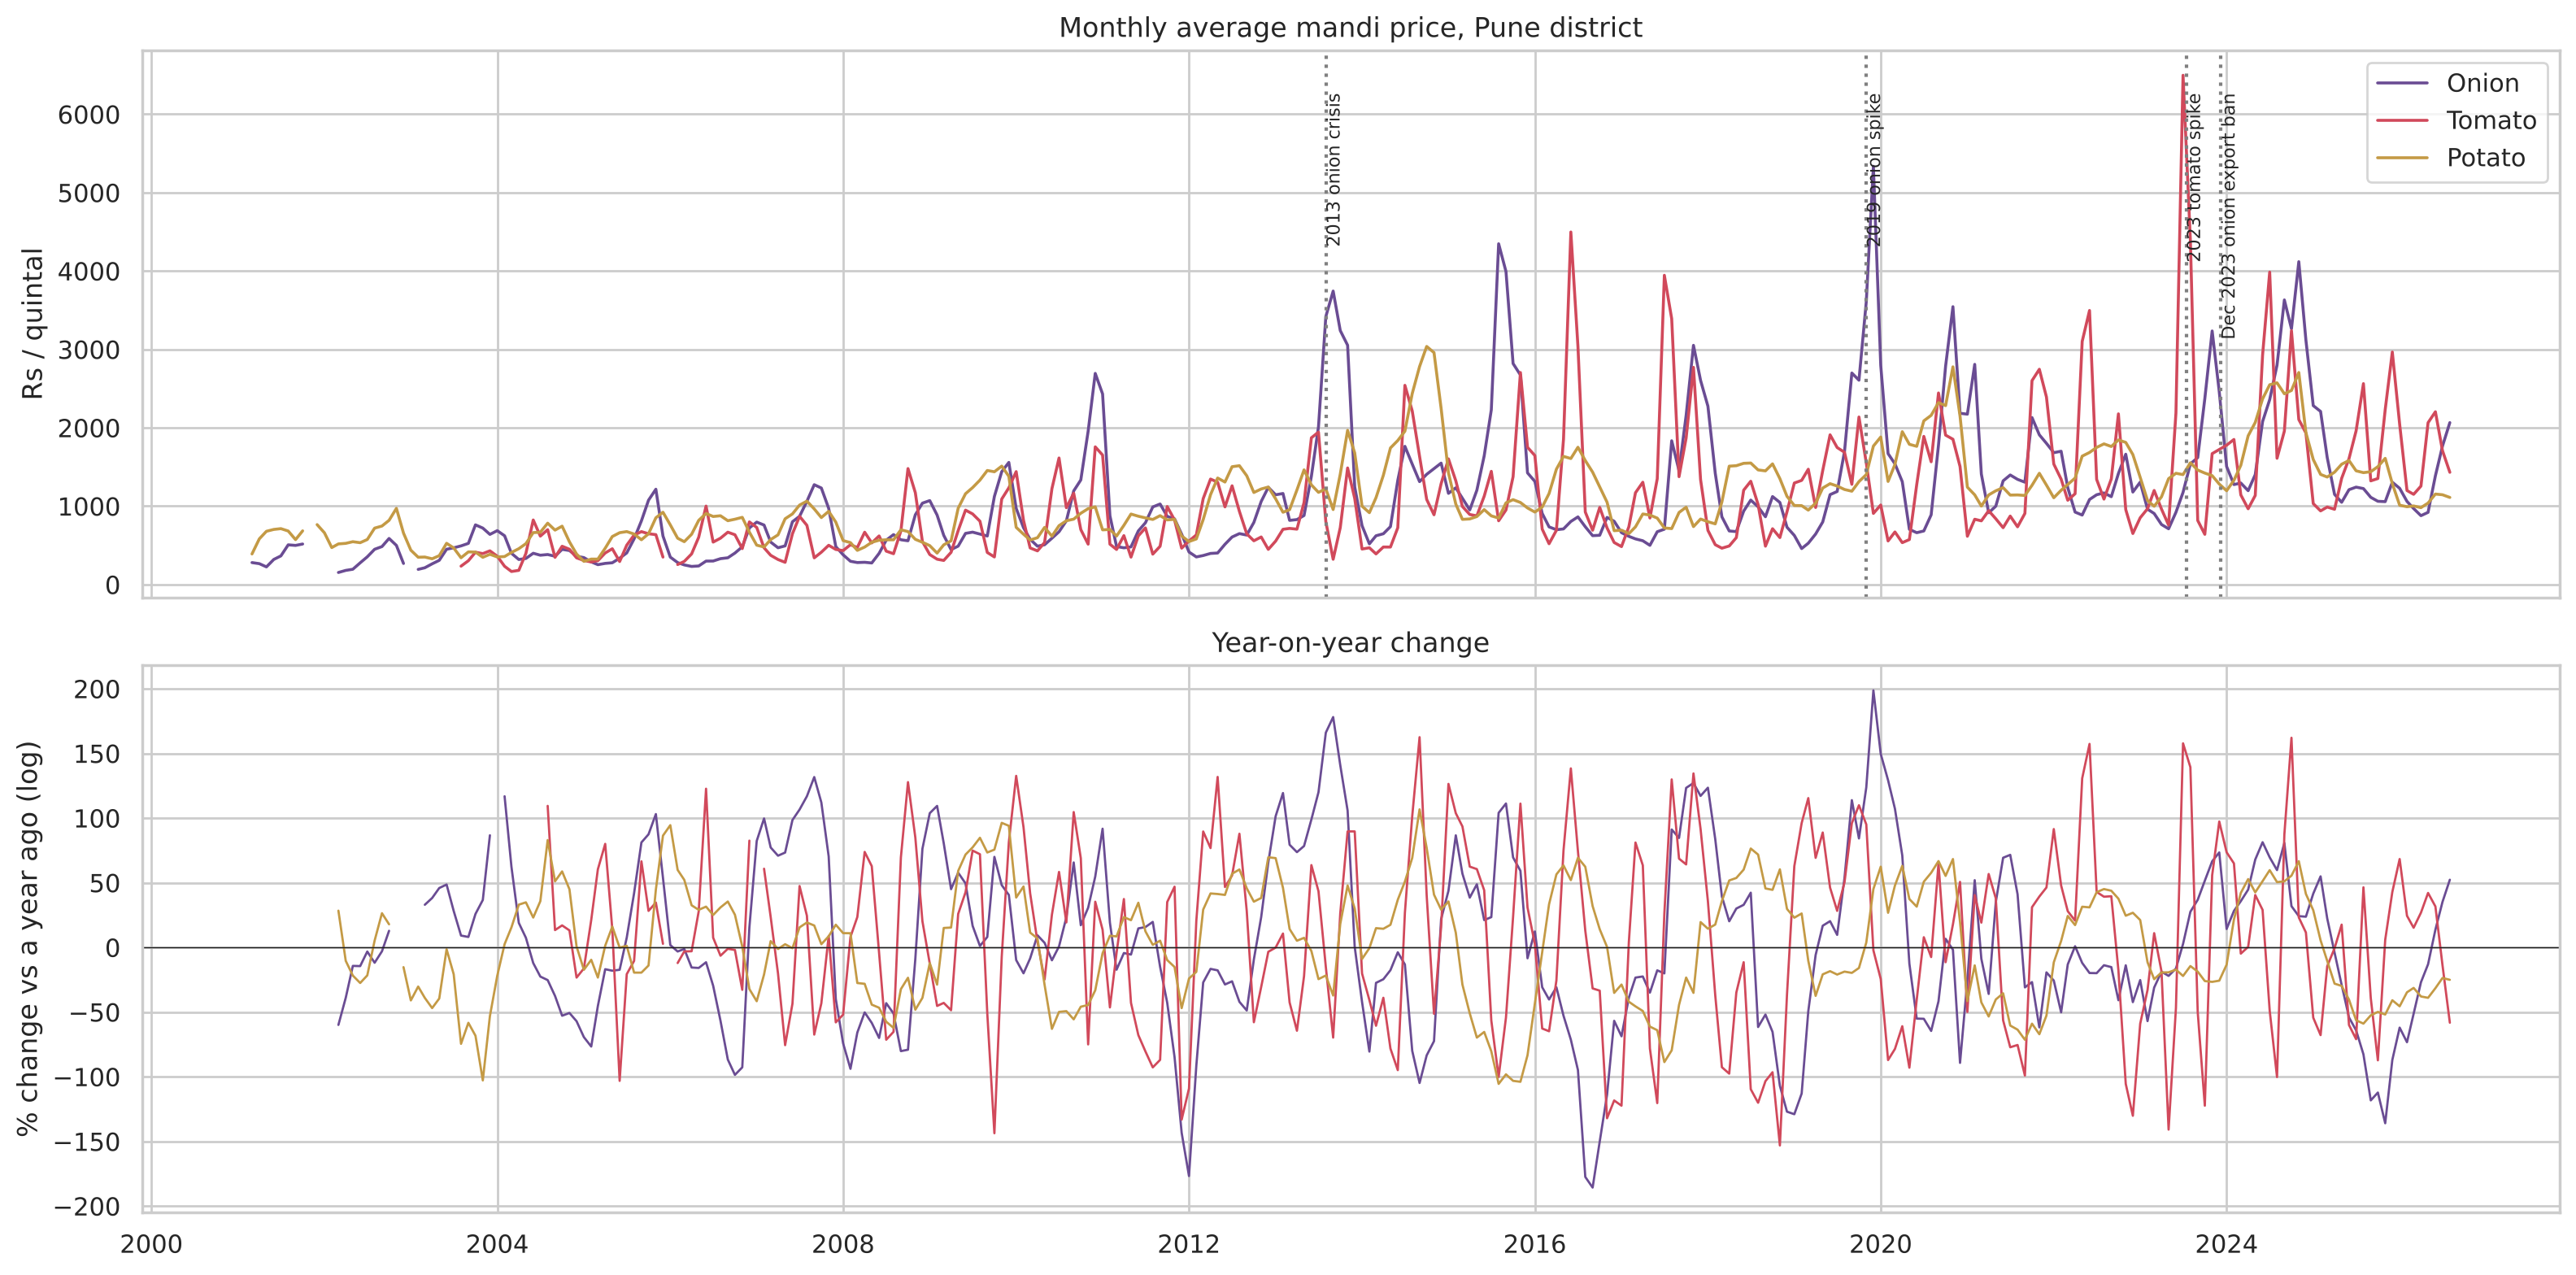

In [4]:
daily = prices.groupby(["crop", "date"]).modal.median().unstack(0)
monthly = daily.resample("MS").mean()
fig, ax = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for c in CROPS:
    ax[0].plot(monthly.index, monthly[c], label=c, color=CROP_COLORS[c], lw=1.3)
ax[0].set_ylabel("Rs / quintal"); ax[0].set_title("Monthly average mandi price, Pune district"); ax[0].legend()
for ev, d in [("2013 onion crisis", "2013-08-01"), ("2019 onion spike", "2019-11-01"),
              ("2023 tomato spike", "2023-07-15"), ("Dec 2023 onion export ban", "2023-12-08")]:
    ax[0].axvline(pd.Timestamp(d), ls=":", c="grey"); ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1]*0.92, " " + ev, fontsize=8, rotation=90, va="top")
yoy = np.log(monthly).diff(12)
for c in CROPS:
    ax[1].plot(yoy.index, yoy[c] * 100, color=CROP_COLORS[c], lw=1)
ax[1].axhline(0, c="k", lw=.5); ax[1].set_ylabel("% change vs a year ago (log)"); ax[1].set_title("Year-on-year change")
plt.tight_layout(); plt.savefig(FIG / "eda_price_history.png", dpi=120); plt.show()

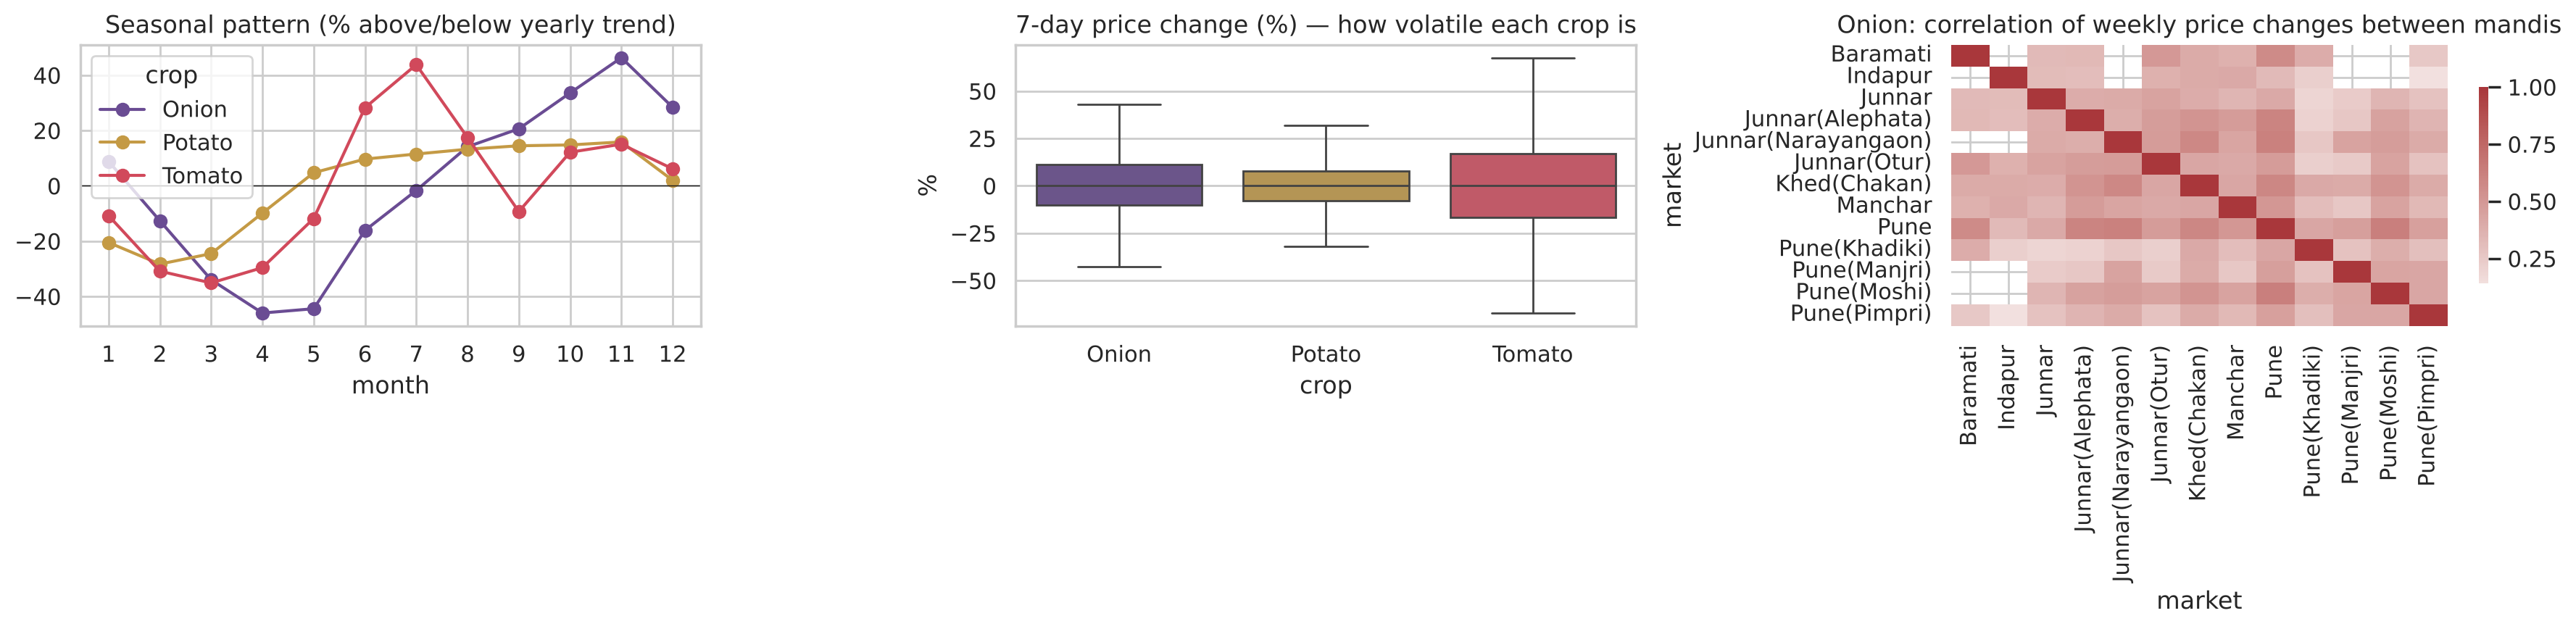

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
season = np.log(daily).sub(np.log(daily).rolling(365, center=True, min_periods=200).mean())
season = season.groupby(season.index.month).mean() * 100
season.plot(ax=ax[0], color=[CROP_COLORS[c] for c in season.columns], marker="o")
ax[0].axhline(0, c="k", lw=.5); ax[0].set_xticks(range(1, 13)); ax[0].set_title("Seasonal pattern (% above/below yearly trend)")
ax[0].set_xlabel("month")

wk = np.log(daily).diff(7) * 100
sns.boxplot(data=wk.melt(var_name="crop", value_name="chg").dropna(), x="crop", y="chg", ax=ax[1],
            palette=CROP_COLORS, showfliers=False)
ax[1].set_title("7-day price change (%) — how volatile each crop is"); ax[1].set_ylabel("%")

mk = prices[prices.crop == "Onion"].pivot_table(index="date", columns="market", values="modal")
mk = np.log(mk.resample("W").mean()).diff()
sns.heatmap(mk.corr(min_periods=100), cmap="vlag", center=0, ax=ax[2], cbar_kws={"shrink": .7})
ax[2].set_title("Onion: correlation of weekly price changes between mandis")
plt.tight_layout(); plt.savefig(FIG / "eda_season_volatility.png", dpi=120); plt.show()

**What the data tells us**
* **Seasonality is strong**: onion is cheapest right after the *rabi* harvest (March–May) and dearest in
  September–November before the *kharif* crop arrives; tomato peaks in the monsoon months.
* **Tomato is by far the most volatile** crop; potato the calmest. A single model must handle both.
* **Mandis move together** (high correlation), so the *crop-wide* trend across all mandis is a useful signal for
  each single mandi.
* Big shocks come from **policy** (export bans and duties) and **weather** — the model can see weather, but not
  government decisions. That limits how well any model can do.

## 4. Features and targets

For every crop, mandi and trading day *t* we compute **35 inputs**, all from information available by the end of day *t*:

| Group | Examples |
|---|---|
| Recent price moves | change over the last 1, 3, 7, 14, 30, 60, 90, 365 days |
| Position vs averages | price vs its 7/30/90/365-day average; volatility; 30-day high-low range; daily min-max spread |
| Crop-wide trend | median change across all mandis; this mandi's price vs the district median |
| Season | day of year (as sine/cosine), month |
| Weather | rain over the last 7/30/90 days, rain vs the normal for this time of year, temperature, humidity |
| Category | crop, mandi |

**Target** for horizon *H*: `log(price on day t+H) − log(price on day t)`, i.e. the % change over the next *H* days.
Predicting the *change* rather than the price lets one model serve a Rs 400 tomato and a Rs 4,000 onion alike.

In [6]:
t0 = time.time()
ds = build_dataset(prices, weather)
MARKETS = sorted(prices.market.unique())
print(f"Feature table: {ds.shape[0]:,} rows x {len(FEATURES)} features, built in {time.time()-t0:.1f}s")
ds[["date", "crop", "market", "price"] + FEATURES[:6] + ["y_7", "y_14", "y_30"]].tail(4)

Feature table: 74,721 rows x 35 features, built in 1.0s


,date,crop,market,price,log_price,ret_1,ret_3,ret_7,ret_14,ret_30,y_7,y_14,y_30
74717,2026-08-19,Tomato,Khed(Chakan),1500.0,7.313221,0.000000,0.068993,0.000000,0.000000,-0.287682,NaN,NaN,NaN
74718,2026-08-19,Tomato,Pune(Khadiki),1050.0,6.956545,-0.046520,0.000000,-0.046520,-0.046520,0.048790,NaN,NaN,NaN
74719,2026-08-19,Tomato,Pune(Manjri),1500.0,7.313221,0.000000,-0.287682,0.000000,0.000000,-0.287682,NaN,NaN,NaN
74720,2026-08-19,Tomato,Pune(Pimpri),1200.0,7.090077,-0.189242,-0.117783,-0.223144,-0.377294,-0.606136,NaN,NaN,NaN


## 5. Validation design — no peeking into the future

Shuffled K-fold, the default for most projects, is **wrong for time series**: it trains on 2024 and tests on 2019,
leaking future information and giving falsely good scores. Instead:

* **Hold-out test = 1 Jan 2023 → Aug 2026** (3.6 years, about a third of the rows), never used for training or tuning.
  It includes extreme events: the July 2023 tomato spike and the December 2023 onion export ban.
* **Training = 2001 → 2022.** Rows whose target date (t + H) falls in 2023 are **purged**, otherwise the last training
  rows would contain test-period prices.
* **Walk-forward cross-validation** for tuning: train on everything before year *Y*, validate on year *Y*, for
  Y = 2018 … 2022 (5 folds, each with a gap of H days).

Main horizon for comparing models: **14 days** (two weeks — long enough to matter for a selling decision).

In [7]:
H = 14
CUT = pd.Timestamp("2023-01-01")
lab = ds[ds[f"y_{H}"].notna()].reset_index(drop=True)
train = lab[lab.date + pd.Timedelta(days=H) < CUT].reset_index(drop=True)
test = lab[lab.date >= CUT].reset_index(drop=True)
Xtr, ytr, Xte, yte = train[FEATURES], train[f"y_{H}"].values, test[FEATURES], test[f"y_{H}"].values

def walk_forward(df, h, years=range(2018, 2023)):
    for y in years:
        start = pd.Timestamp(f"{y}-01-01")
        tr = np.where(df.date + pd.Timedelta(days=h) < start)[0]
        va = np.where((df.date >= start) & (df.date < pd.Timestamp(f"{y+1}-01-01")))[0]
        yield tr, va
CV = list(walk_forward(train, H))
print(f"train {len(train):,} rows (to {train.date.max():%b %Y}) | test {len(test):,} rows ({test.date.min():%b %Y} - {test.date.max():%b %Y})")
print("walk-forward folds:", [(len(a), len(b)) for a, b in CV])

train 45,235 rows (to Dec 2022) | test 23,282 rows (Jan 2023 - Aug 2026)
walk-forward folds: [(24159, 2973), (27070, 3468), (30550, 3017), (33567, 5590), (39031, 5947)]


## 6. Baselines and classic models

A forecasting model is only useful if it beats simple rules a farmer could apply in his head:
* **Naive**: "in two weeks the price will be the same as today" (very hard to beat in markets).
* **Moving average**: "the price will return to its 30-day average".

Metrics (on the price in rupees):
**MAE** (average error in Rs/quintal), **MAPE** (average % error), **skill** (= how much lower the MAE is than the
naive forecast's), **R²** of the % change, and **direction accuracy** (did we get *up vs down* right?).
Linear models, KNN and SVR need missing values filled and features scaled, so they run inside a `Pipeline`.
The kernel SVR is trained on 15,000 rows because it scales with the square of the data size.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

P_te = test.price.values
NUM = [f for f in FEATURES if f not in ("crop_code", "market_code")]
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), ["crop_code", "market_code"])])

def evaluate(name, pred_ret, y=yte, P=P_te, extra=None):
    actual, fc = P * np.exp(y), P * np.exp(pred_ret)
    naive_mae = np.mean(np.abs(P - actual))
    mae = np.mean(np.abs(fc - actual))
    moved = np.abs(y) > 0.02
    row = dict(model=name, MAE_Rs=mae, MAPE=np.mean(np.abs(fc - actual) / actual), skill_vs_naive=1 - mae / naive_mae,
               R2=r2_score(y, pred_ret), direction_acc=np.mean(np.sign(pred_ret[moved]) == np.sign(y[moved])))
    row.update(extra or {})
    return row

results = [evaluate("Naive (no change)", np.zeros(len(test))),
           evaluate("30-day moving average", -test["dev_ma30"].fillna(0).values)]
rng = np.random.RandomState(SEED)
classic = {
    "Linear Regression": make_pipeline(pre, LinearRegression()),
    "Ridge": make_pipeline(pre, Ridge(alpha=10)),
    "Lasso": make_pipeline(pre, Lasso(alpha=0.001)),
    "KNN (k=50)": make_pipeline(pre, KNeighborsRegressor(n_neighbors=50)),
    "Decision Tree": make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(max_depth=8, min_samples_leaf=100, random_state=SEED)),
    "SVR (RBF)": make_pipeline(pre, SVR(C=0.3, epsilon=0.05)),
}
fitted = {}
for name, m in classic.items():
    t0 = time.time()
    idx = rng.choice(len(train), 15000, replace=False) if name.startswith("SVR") else np.arange(len(train))
    m.fit(Xtr.iloc[idx], ytr[idx]); fitted[name] = m
    results.append(evaluate(name, m.predict(Xte), extra={"train_s": time.time() - t0}))
    print(f"{name:20s} MAE Rs {results[-1]['MAE_Rs']:6.1f} | skill {results[-1]['skill_vs_naive']:+.1%}")
pd.DataFrame(results).set_index("model").round(3)

Linear Regression    MAE Rs  322.7 | skill +9.9%
Ridge                MAE Rs  322.7 | skill +9.9%


Lasso                MAE Rs  321.9 | skill +10.1%


KNN (k=50)           MAE Rs  329.9 | skill +7.9%


Decision Tree        MAE Rs  369.4 | skill -3.2%


SVR (RBF)            MAE Rs  334.1 | skill +6.7%


,MAE_Rs,MAPE,skill_vs_naive,R2,direction_acc,train_s
model,,,,,,
Naive (no change),358.087,0.210,0.000,-0.000,0.000,NaN
30-day moving average,471.950,0.287,-0.318,-0.603,0.559,NaN
Linear Regression,322.699,0.186,0.099,0.255,0.674,0.344
Ridge,322.658,0.186,0.099,0.256,0.674,0.158
Lasso,321.885,0.185,0.101,0.260,0.673,0.221
KNN (k=50),329.887,0.190,0.079,0.211,0.660,3.634
Decision Tree,369.401,0.208,-0.032,0.036,0.612,0.714
SVR (RBF),334.107,0.194,0.067,0.202,0.667,27.023


## 7. Ensembles and hyper-parameter tuning

* **Random Forest** (bagging), **Gradient Boosting** (`HistGradientBoostingRegressor`, boosting with native support
  for missing values and categories), **XGBoost**.
* Gradient Boosting is trained with **absolute-error loss**: price data has huge spikes, and squared error lets a few
  spikes dominate training.
* **GridSearchCV with the walk-forward folds** tunes learning rate, tree size and leaf size (scored by MAE).

In [9]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

CAT = ["crop_code", "market_code"]
def hgb(**kw):
    base = dict(loss="absolute_error", max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                l2_regularization=1.0, categorical_features=CAT, random_state=SEED)
    base.update(kw); return HistGradientBoostingRegressor(**base)

ens = {
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.4, n_jobs=2, random_state=SEED)),
    "Gradient Boosting": hgb(),
    "XGBoost": XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                            objective="reg:absoluteerror", n_jobs=2, random_state=SEED),
}
for name, m in ens.items():
    t0 = time.time(); m.fit(Xtr, ytr); fitted[name] = m
    results.append(evaluate(name, m.predict(Xte), extra={"train_s": time.time() - t0}))
    print(f"{name:20s} MAE Rs {results[-1]['MAE_Rs']:6.1f} | skill {results[-1]['skill_vs_naive']:+.1%}")

Random Forest        MAE Rs  326.1 | skill +8.9%


Gradient Boosting    MAE Rs  329.7 | skill +7.9%


XGBoost              MAE Rs  327.0 | skill +8.7%


In [10]:
grid = GridSearchCV(hgb(), {"learning_rate": [0.03, 0.06], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [50, 200]},
                    scoring="neg_mean_absolute_error", cv=CV, n_jobs=2)
t0 = time.time(); grid.fit(Xtr, ytr)
BEST = grid.best_params_
print(f"GridSearchCV: {len(grid.cv_results_['params'])} settings x {len(CV)} walk-forward folds in {time.time()-t0:.0f}s")
print("Best:", BEST, f"| CV MAE (log change) {-grid.best_score_:.4f}")
cvres = pd.DataFrame(grid.cv_results_)
display(cvres[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5))

best_model = hgb(**BEST).fit(Xtr, ytr); fitted["Gradient Boosting (tuned)"] = best_model
results.append(evaluate("Gradient Boosting (tuned)", best_model.predict(Xte)))

GridSearchCV: 12 settings x 5 walk-forward folds in 156s
Best: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 200} | CV MAE (log change) 0.2090


,params,mean_test_score,std_test_score,rank_test_score
1,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",-0.209033,0.021504,1
0,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",-0.209386,0.020356,2
2,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",-0.210194,0.021919,3
3,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",-0.210617,0.020951,4
4,"{'learning_rate': 0.03, 'max_leaf_nodes': 63, ...",-0.211951,0.021979,5


In [11]:
# Per-fold walk-forward scores of the tuned model: is it stable year to year?
rows = []
for (tr, va), y in zip(CV, range(2018, 2023)):
    m = hgb(**BEST).fit(Xtr.iloc[tr], ytr[tr]); p = m.predict(Xtr.iloc[va])
    r = evaluate(str(y), p, y=ytr[va], P=train.price.values[va]); rows.append(r)
wf = pd.DataFrame(rows).rename(columns={"model": "validation year"}).set_index("validation year")
print("Walk-forward validation of the tuned model (train on all years before, test on that year):")
display(wf[["MAE_Rs", "MAPE", "skill_vs_naive", "direction_acc"]].round(3))

Walk-forward validation of the tuned model (train on all years before, test on that year):


,MAE_Rs,MAPE,skill_vs_naive,direction_acc
validation year,,,,
2018,180.845,0.202,0.090,0.684
2019,383.119,0.220,0.055,0.618
2020,376.513,0.245,0.109,0.693
2021,271.487,0.193,0.044,0.638
2022,278.923,0.196,0.101,0.678


,MAE_Rs,MAPE,skill_vs_naive,R2,direction_acc
model,,,,,
Lasso,321.885,0.185,0.101,0.260,0.673
Ridge,322.658,0.186,0.099,0.256,0.674
Linear Regression,322.699,0.186,0.099,0.255,0.674
Gradient Boosting (tuned),323.267,0.183,0.097,0.243,0.694
Random Forest,326.130,0.186,0.089,0.227,0.676
XGBoost,326.983,0.191,0.087,0.216,0.689
Gradient Boosting,329.661,0.189,0.079,0.216,0.684
KNN (k=50),329.887,0.190,0.079,0.211,0.660
SVR (RBF),334.107,0.194,0.067,0.202,0.667


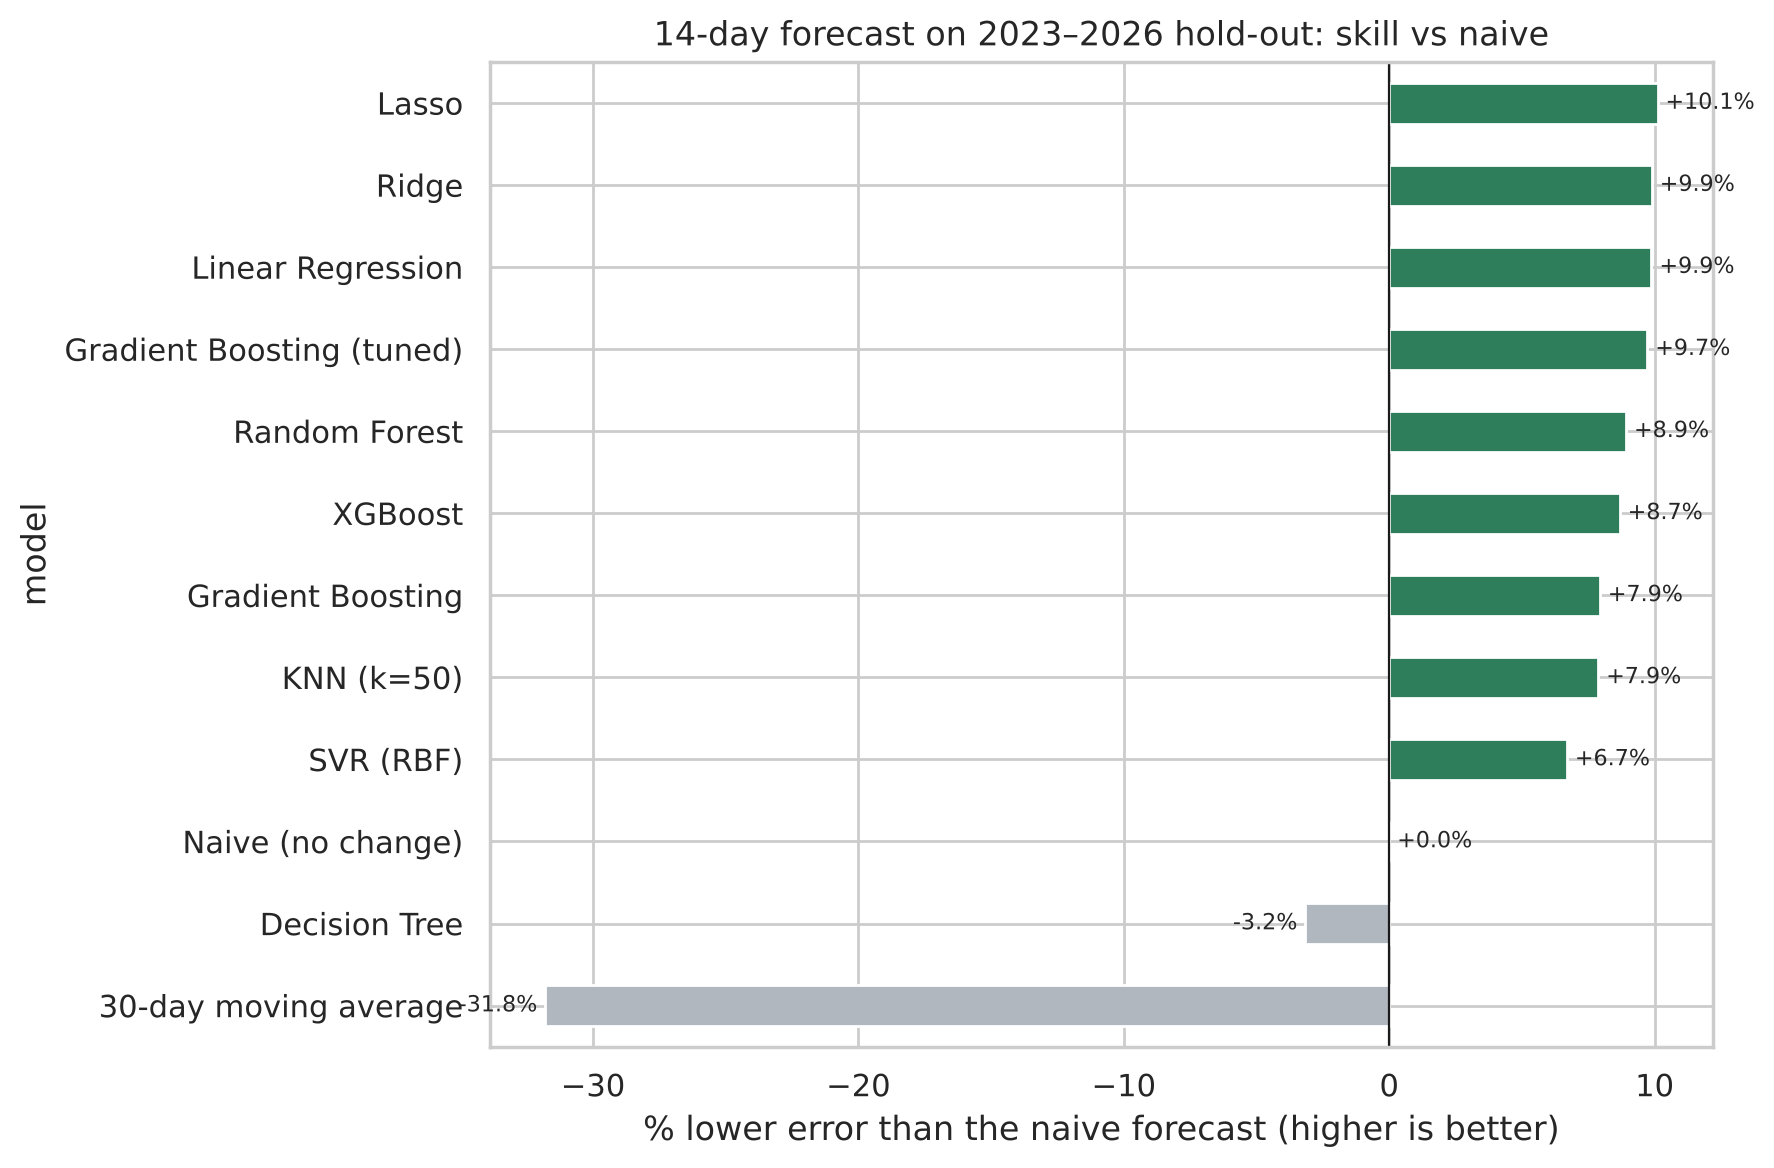

In [12]:
res = pd.DataFrame(results).set_index("model")
display(res[["MAE_Rs", "MAPE", "skill_vs_naive", "R2", "direction_acc"]].round(3).sort_values("MAE_Rs"))
s = res["skill_vs_naive"].sort_values()
ax = s.mul(100).plot.barh(figsize=(9, 6), color=["#2E7D5B" if v > 0 else "#B0B7BF" for v in s])
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("% lower error than the naive forecast (higher is better)")
ax.set_title(f"{H}-day forecast on 2023–2026 hold-out: skill vs naive")
for i, v in enumerate(s): ax.text(v*100 + (0.3 if v >= 0 else -0.3), i, f"{v:+.1%}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=120); plt.show()

**Reading the table:** beating "no change" is genuinely hard in markets — the single decision tree and the
moving-average rule do *worse* than naive on 2023–2026. The best models cut the error by about 10%, and they are
close to each other: the linear models and the tuned gradient boosting are within Rs 2 per quintal.
**Tuned gradient boosting is chosen for the final forecasts** because, at the same accuracy, it
* gets the *direction* (up or down) right most often (69%),
* handles missing values and the crop / mandi categories natively, and
* can be trained with *quantile loss* to give a likely price **range** (Section 11), which a farmer needs more than
  a single number.

## 8. PCA — dimensionality reduction

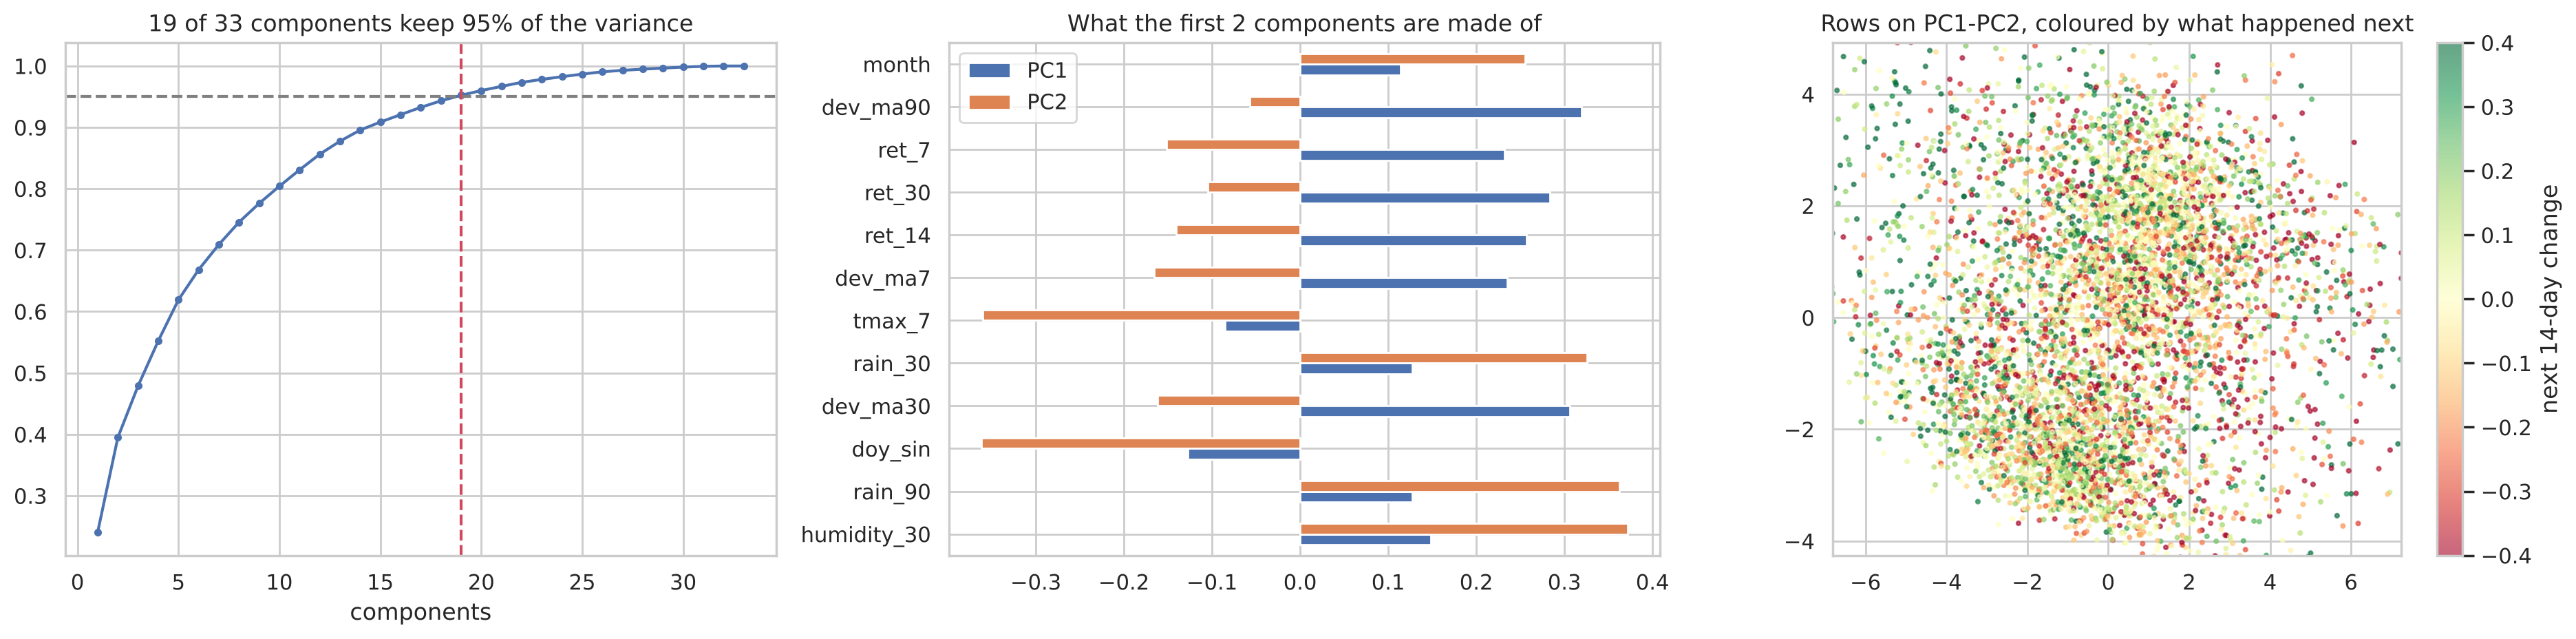

Ridge on  3 PCA components -> skill vs naive -0.6%
Ridge on 10 PCA components -> skill vs naive +7.7%


Ridge on 19 PCA components -> skill vs naive +8.3%


In [13]:
from sklearn.decomposition import PCA
imp_scaler = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(Xtr[NUM])
Z = imp_scaler.transform(Xtr[NUM]); pca = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_); k95 = int(np.argmax(cum >= .95) + 1)

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o", ms=3); ax[0].axhline(.95, ls="--", c="grey"); ax[0].axvline(k95, ls="--", c="#D1495B")
ax[0].set_title(f"{k95} of {len(NUM)} components keep 95% of the variance"); ax[0].set_xlabel("components")
load = pd.DataFrame(pca.components_[:2].T, index=NUM, columns=["PC1", "PC2"])
top = load.abs().sum(axis=1).sort_values(ascending=False).index[:12]
load.loc[top].plot.barh(ax=ax[1]); ax[1].set_title("What the first 2 components are made of")
sub = rng.choice(len(Z), 6000, replace=False); P2 = pca.transform(Z[sub])[:, :2]
sc = ax[2].scatter(*P2.T, c=np.clip(ytr[sub], -.4, .4), cmap="RdYlGn", s=4, alpha=.6)
ax[2].set_xlim(np.percentile(P2[:, 0], [1, 99])); ax[2].set_ylim(np.percentile(P2[:, 1], [1, 99]))
plt.colorbar(sc, ax=ax[2], label="next 14-day change"); ax[2].set_title("Rows on PC1-PC2, coloured by what happened next")
plt.tight_layout(); plt.savefig(FIG / "pca.png", dpi=120); plt.show()

for k in [3, 10, k95]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(k, random_state=SEED), Ridge(alpha=10)).fit(Xtr[NUM], ytr)
    print(f"Ridge on {k:2d} PCA components -> skill vs naive {evaluate('', m.predict(Xte[NUM]))['skill_vs_naive']:+.1%}")

**Takeaway:** the first components are mostly "where is the price compared with its averages" and "how volatile is
the market". In the 2-D view, future rises and falls are thoroughly mixed — there is no simple straight-line
separation, which is why tree ensembles beat linear models here.

## 9. K-Means — what "mood" is the market in?

We cluster trading days by **recent momentum, position vs the 90-day average and volatility** to find recurring
*market regimes*, without telling K-Means anything about the future. Then we check whether the regime says something
about the *next* two weeks.

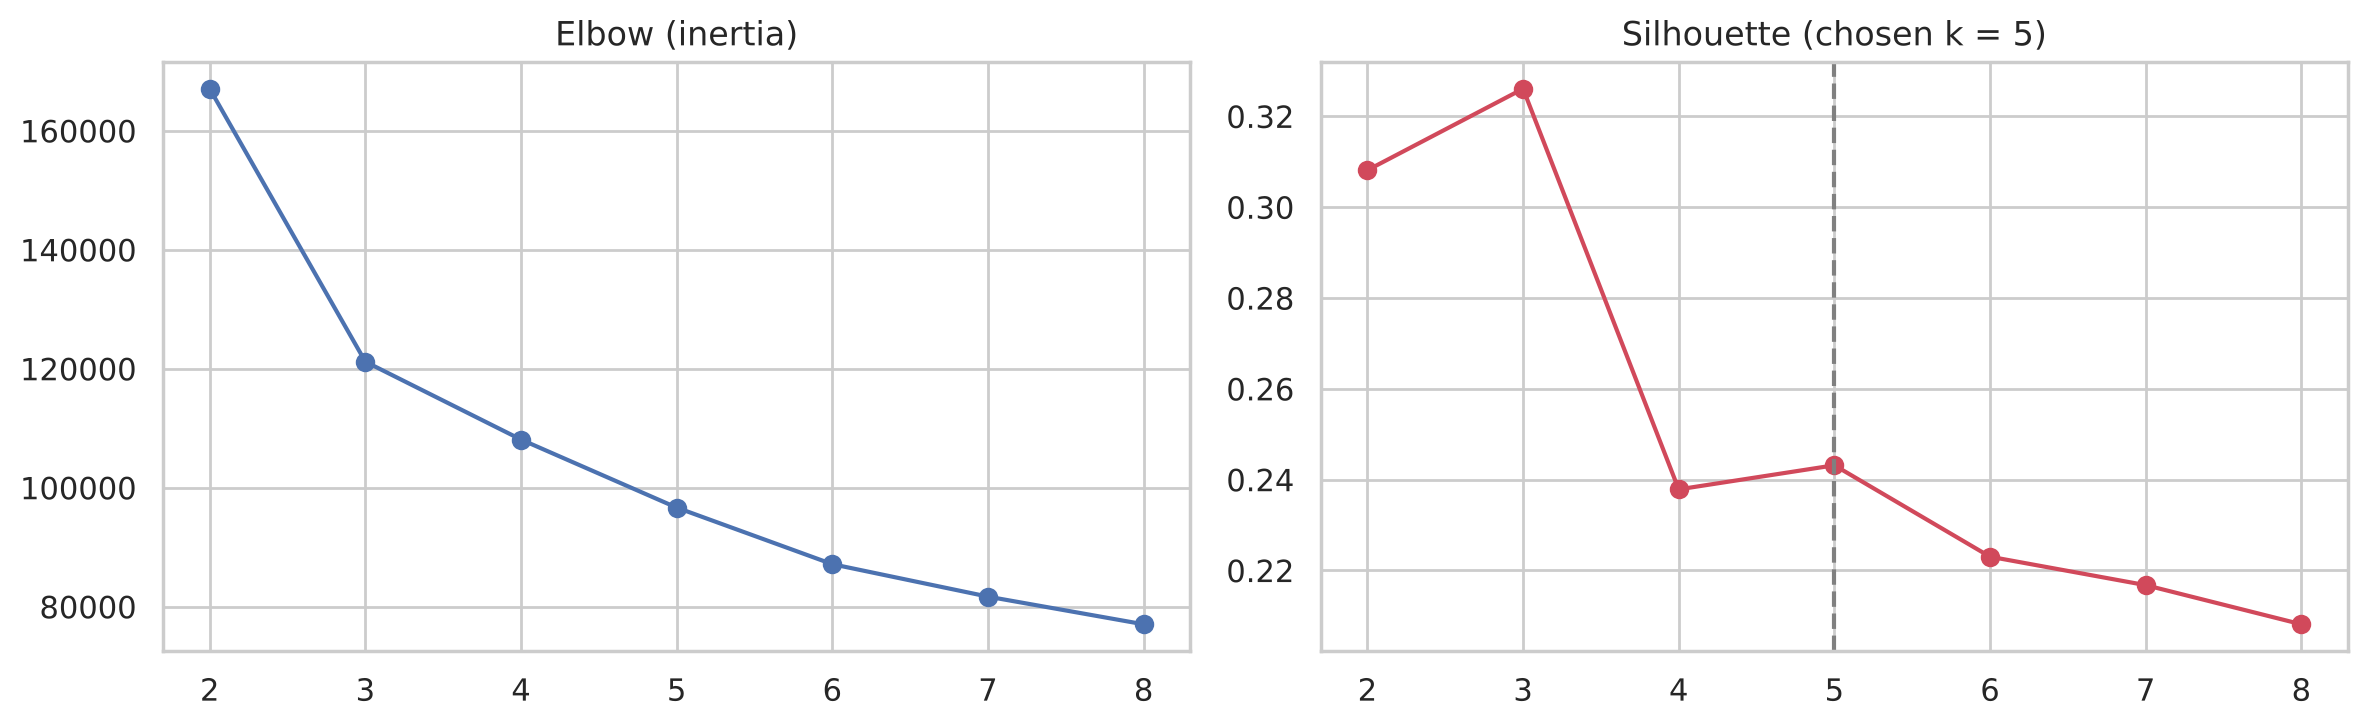

,ret_7,ret_30,dev_ma90,vol_30,range_30
regime,,,,,
0: calm / normal,0.038,0.084,0.086,0.087,0.373
1: choppy / volatile,0.045,0.071,0.023,0.225,0.913
2: spike (far above average),0.329,0.747,0.590,0.186,1.057
"3: below average, falling",-0.130,-0.263,-0.351,0.130,0.581
4: crash (far below average),-0.337,-0.749,-0.723,0.218,1.141


,share_of_days,avg_next_14d_change,chance_of_5pct_rise
regime,,,
0: calm / normal,0.426,-0.005,0.369
1: choppy / volatile,0.166,-0.031,0.388
2: spike (far above average),0.102,-0.064,0.357
"3: below average, falling",0.221,0.026,0.443
4: crash (far below average),0.085,0.078,0.483


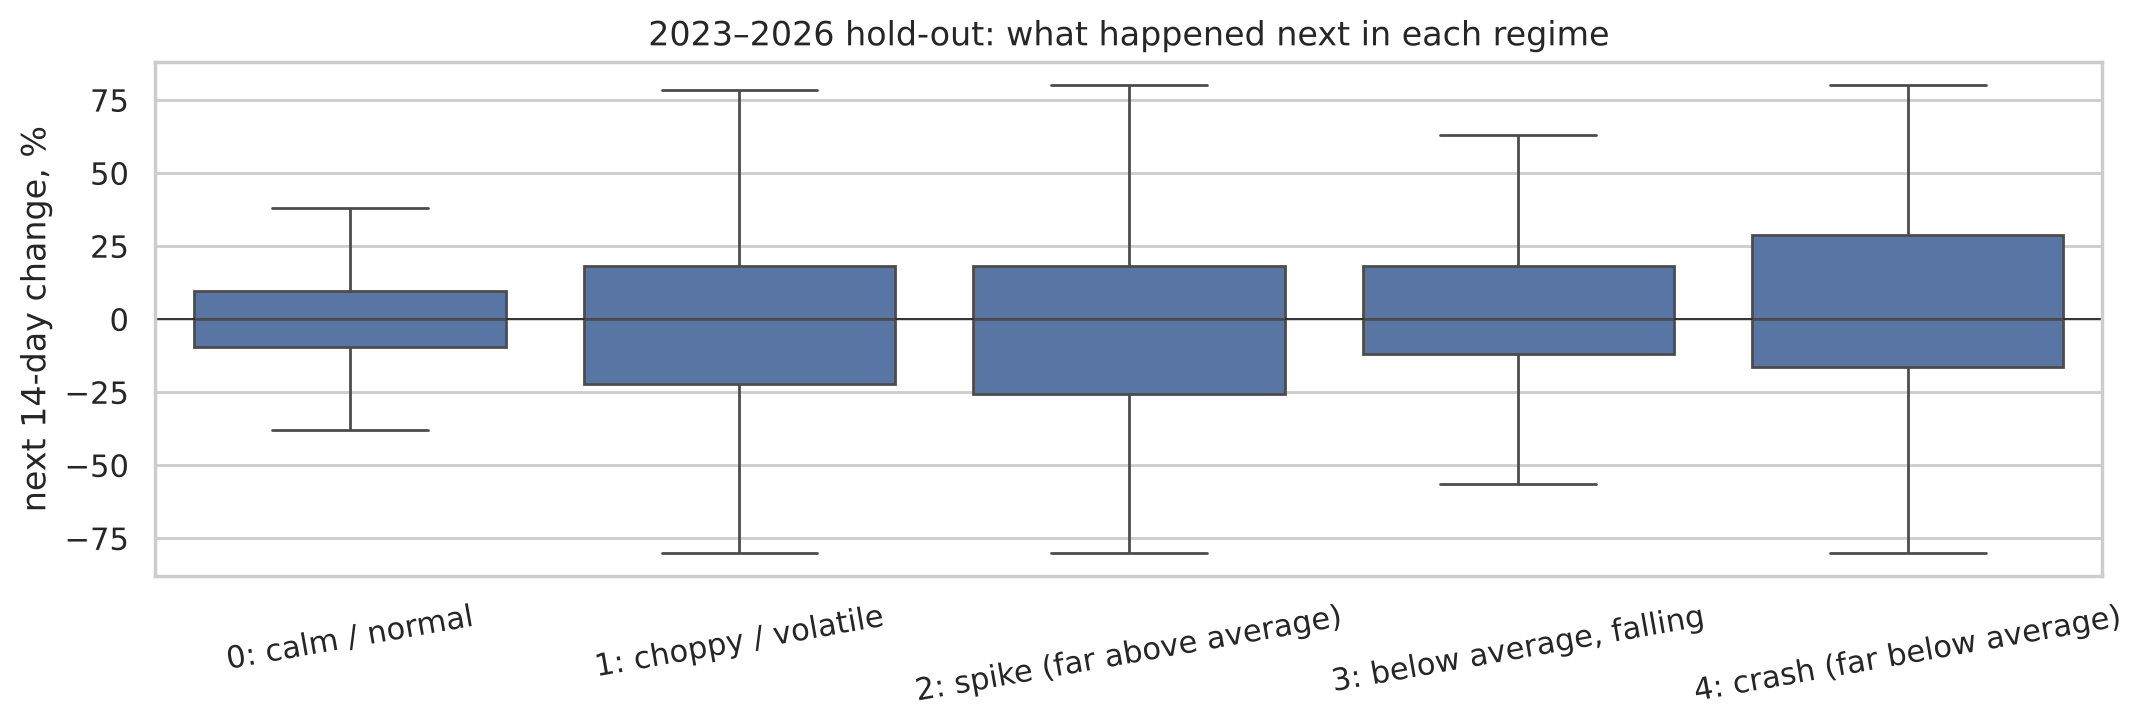

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
RF = ["ret_7", "ret_30", "dev_ma90", "vol_30", "range_30"]
reg_scaler = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(Xtr[RF])
Zr = reg_scaler.transform(Xtr[RF]); sidx = rng.choice(len(Zr), 6000, replace=False)
ks, inertia, sil = list(range(2, 9)), [], []
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEED).fit(Zr); inertia.append(km.inertia_); sil.append(silhouette_score(Zr[sidx], km.labels_[sidx]))
K = ks[int(np.argmax(sil[2:])) + 2]   # k >= 4 so the regimes are informative
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[1].plot(ks, sil, marker="o", c="#D1495B")
ax[1].axvline(K, ls="--", c="grey"); ax[1].set_title(f"Silhouette (chosen k = {K})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_choose_k.png", dpi=120); plt.show()

km = KMeans(K, n_init=10, random_state=SEED).fit(Zr)
cent = pd.DataFrame(reg_scaler[-1].inverse_transform(km.cluster_centers_), columns=RF)
def name_regime(r):
    if r.dev_ma90 > .3: return "spike (far above average)"
    if r.dev_ma90 < -.5: return "crash (far below average)"
    if r.dev_ma90 < -.15: return "below average, falling"
    if r.vol_30 > .2: return "choppy / volatile"
    return "calm / normal"
cent["regime"] = [f"{i}: {name_regime(r)}" for i, r in cent.iterrows()]
train_reg = pd.Series(km.labels_).map(cent.regime)
summary = (pd.DataFrame({"regime": train_reg, "next14": ytr}).groupby("regime").next14
           .agg(share_of_days=lambda s: len(s) / len(ytr), avg_next_14d_change="mean",
                chance_of_5pct_rise=lambda s: (s > np.log(1.05)).mean()))
display(cent.set_index("regime")[RF].round(3)); display(summary.round(3))

test_reg = pd.Series(km.predict(reg_scaler.transform(Xte[RF]))).map(cent.regime)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.boxplot(x=test_reg, y=np.clip(yte, -.8, .8) * 100, ax=ax, showfliers=False, order=sorted(cent.regime))
ax.axhline(0, c="k", lw=.6); ax.set_ylabel("next 14-day change, %"); ax.set_xlabel("")
ax.set_title("2023–2026 hold-out: what happened next in each regime"); plt.xticks(rotation=10)
plt.tight_layout(); plt.savefig(FIG / "kmeans_regimes.png", dpi=120); plt.show()

The regimes found on 2001–2022 data still separate what happened next on the unseen 2023–2026 data: after a price
has run far above its 90-day average, it tends to fall back (*mean reversion*), and after a crash it tends to
recover. This is the same pattern the gradient-boosting model exploits — clustering makes it visible.

## 10. Classification: will the price rise by 5% or more in the next 14 days?

For a farmer, *"is it worth waiting?"* is a yes/no question. About a third of all days are followed by a 5%+ rise.

,ROC_AUC,accuracy,precision,recall,F1
model,,,,,
Logistic Regression,0.716,0.690,0.687,0.389,0.496
Random Forest,0.728,0.688,0.663,0.419,0.513
Gradient Boosting,0.727,0.688,0.651,0.444,0.528
Always 'no rise' (baseline),0.500,0.608,0.000,0.000,0.000


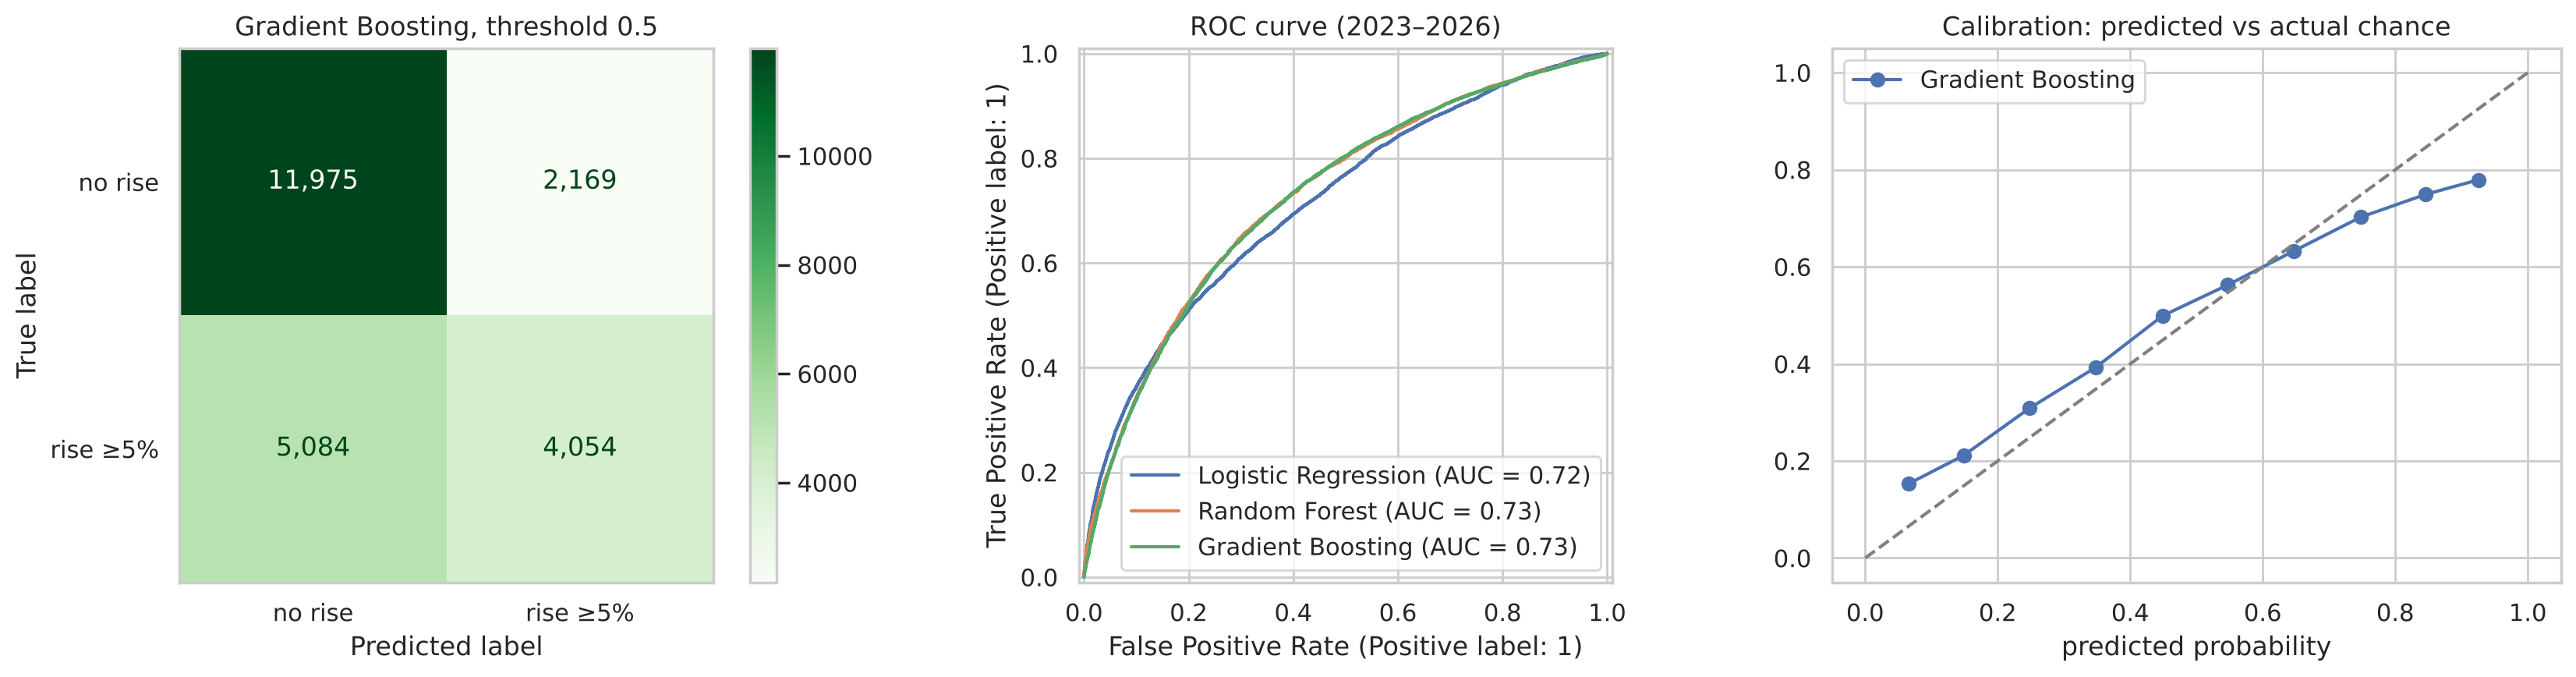

When the model says >= 60% chance (18% of days), a 5%+ rise really followed 69% of the time (vs 39% on an average day).


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import calibration_curve

RISE = np.log(1.05)
ctr, cte = (ytr > RISE).astype(int), (yte > RISE).astype(int)
clfs = {
    "Logistic Regression": make_pipeline(pre, LogisticRegression(max_iter=3000, C=0.3)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.4, n_jobs=2, random_state=SEED)),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=100,
                                                        l2_regularization=1.0, categorical_features=CAT, random_state=SEED),
}
crow, probs = [], {}
for name, m in clfs.items():
    m.fit(Xtr, ctr); p = m.predict_proba(Xte)[:, 1]; probs[name] = p
    crow.append(dict(model=name, ROC_AUC=roc_auc_score(cte, p), accuracy=accuracy_score(cte, p >= .5),
                     precision=precision_score(cte, p >= .5, zero_division=0), recall=recall_score(cte, p >= .5),
                     F1=f1_score(cte, p >= .5)))
crow.append(dict(model="Always 'no rise' (baseline)", ROC_AUC=.5, accuracy=1 - cte.mean(), precision=0, recall=0, F1=0))
cls_table = pd.DataFrame(crow).set_index("model").round(3); display(cls_table)
rise_clf = clfs["Gradient Boosting"]; p_rise = probs["Gradient Boosting"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(cte, p_rise >= .5), display_labels=["no rise", "rise ≥5%"]).plot(ax=ax[0], cmap="Greens", values_format=",")
ax[0].set_title("Gradient Boosting, threshold 0.5"); ax[0].grid(False)
for name, p in probs.items(): RocCurveDisplay.from_predictions(cte, p, name=name, ax=ax[1])
ax[1].set_title("ROC curve (2023–2026)")
fr, mp = calibration_curve(cte, p_rise, n_bins=10); ax[2].plot(mp, fr, marker="o", label="Gradient Boosting"); ax[2].plot([0, 1], [0, 1], "--", c="grey")
ax[2].set_title("Calibration: predicted vs actual chance"); ax[2].set_xlabel("predicted probability"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "rise_classifier.png", dpi=120); plt.show()

hi = p_rise >= .6
print(f"When the model says >= 60% chance ({hi.mean():.0%} of days), a 5%+ rise really followed {cte[hi].mean():.0%} of the time "
      f"(vs {cte.mean():.0%} on an average day).")

## 11. A likely price range, not just one number

A single number hides how uncertain a forecast is. **Quantile regression** trains three gradient-boosting models
per horizon — for the 10th, 50th and 90th percentile of the future price. The 10–90 band should contain the real
price **about 80% of the time**; we check that on the hold-out (*coverage*).

In [16]:
def quantile_models(Xa, ya, params=BEST):
    out = {}
    for q in (10, 50, 90):
        kw = dict(params); kw.update(loss="quantile", quantile=q / 100)
        out[q] = hgb(**kw).fit(Xa, ya)
    return out

hold = {}
for h in HORIZONS:
    lab_h = ds[ds[f"y_{h}"].notna()]
    tr_h = lab_h[lab_h.date + pd.Timedelta(days=h) < CUT]; te_h = lab_h[lab_h.date >= CUT]
    qm = quantile_models(tr_h[FEATURES], tr_h[f"y_{h}"].values)
    pred = {q: m.predict(te_h[FEATURES]) for q, m in qm.items()}
    lo, mid, hi_ = np.minimum(pred[10], pred[50]), pred[50], np.maximum(pred[90], pred[50])
    y = te_h[f"y_{h}"].values
    r = evaluate(f"{h} days", mid, y=y, P=te_h.price.values)
    r.update(coverage_10_90=np.mean((y >= lo) & (y <= hi_)), avg_band_width=np.mean(np.exp(hi_) - np.exp(lo)))
    hold[h] = dict(row=r, frame=te_h.assign(lo=lo, mid=mid, hi=hi_))
    print(f"{h:2d} days | MAE Rs {r['MAE_Rs']:.0f} | skill vs naive {r['skill_vs_naive']:+.1%} | "
          f"80% band covers {r['coverage_10_90']:.1%} | direction {r['direction_acc']:.1%}")
horizon_table = pd.DataFrame([v["row"] for v in hold.values()]).set_index("model")
display(horizon_table[["MAE_Rs", "MAPE", "skill_vs_naive", "direction_acc", "coverage_10_90", "avg_band_width"]].round(3))

 7 days | MAE Rs 248 | skill vs naive +8.5% | 80% band covers 79.6% | direction 69.5%


14 days | MAE Rs 323 | skill vs naive +9.7% | 80% band covers 75.8% | direction 69.4%


30 days | MAE Rs 436 | skill vs naive +18.2% | 80% band covers 66.5% | direction 70.4%


,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90,avg_band_width
model,,,,,,
7 days,248.469,0.145,0.085,0.695,0.796,0.458
14 days,323.267,0.183,0.097,0.694,0.758,0.538
30 days,435.954,0.246,0.182,0.704,0.665,0.641


**Reading the ranges honestly:** the 7-day range is well calibrated (it contains the real price about 80% of the
time, as intended). Longer ranges are **too narrow** — the 2023–2026 period was more volatile than the training
years, so the 30-day band catches the real price only about two times in three. The app therefore labels ranges as
"likely", and a natural improvement is *conformal calibration* (widening the bands using recent errors).

## 12. Hold-out evaluation 2023–2026

### 12a. Error by crop and by year

In [17]:
f14 = hold[14]["frame"]
def by(col):
    rows = []
    for k, g in f14.groupby(col):
        r = evaluate(str(k), g["mid"].values, y=g["y_14"].values, P=g["price"].values)
        r.update(rows=len(g), coverage_10_90=np.mean((g.y_14 >= g.lo) & (g.y_14 <= g.hi))); rows.append(r)
    return pd.DataFrame(rows).set_index("model")[["rows", "MAE_Rs", "MAPE", "skill_vs_naive", "direction_acc", "coverage_10_90"]].round(3)
print("By crop (14-day forecast)"); display(by("crop"))
print("By year"); display(by(f14.date.dt.year.rename("year")))
print("By mandi"); display(by("market").sort_values("skill_vs_naive", ascending=False))

By crop (14-day forecast)


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
Onion,8748,270.348,0.157,0.114,0.698,0.772
Potato,6718,154.356,0.111,0.053,0.693,0.787
Tomato,7816,527.677,0.275,0.098,0.689,0.717


By year


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
2023,6635,384.896,0.220,0.085,0.699,0.701
2024,6495,384.220,0.181,0.130,0.685,0.751
2025,6348,277.822,0.179,0.038,0.675,0.776
2026,3804,187.536,0.130,0.155,0.734,0.838


By mandi


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
Baramati,242,362.842,0.163,0.163,0.735,0.798
Pune(Pimpri),2433,385.884,0.193,0.131,0.713,0.754
Junnar,328,301.282,0.179,0.125,0.727,0.735
Junnar(Otur),638,248.096,0.178,0.107,0.697,0.832
Pune(Moshi),3188,313.470,0.197,0.107,0.687,0.719
Khed(Chakan),2662,327.451,0.173,0.102,0.724,0.747
Pune(Khadiki),3166,172.450,0.120,0.093,0.697,0.835
Pune(Manjri),3512,402.058,0.212,0.090,0.692,0.689
Junnar(Narayangaon),2374,389.706,0.245,0.082,0.701,0.763


### 12b. Case studies: two famous price shocks

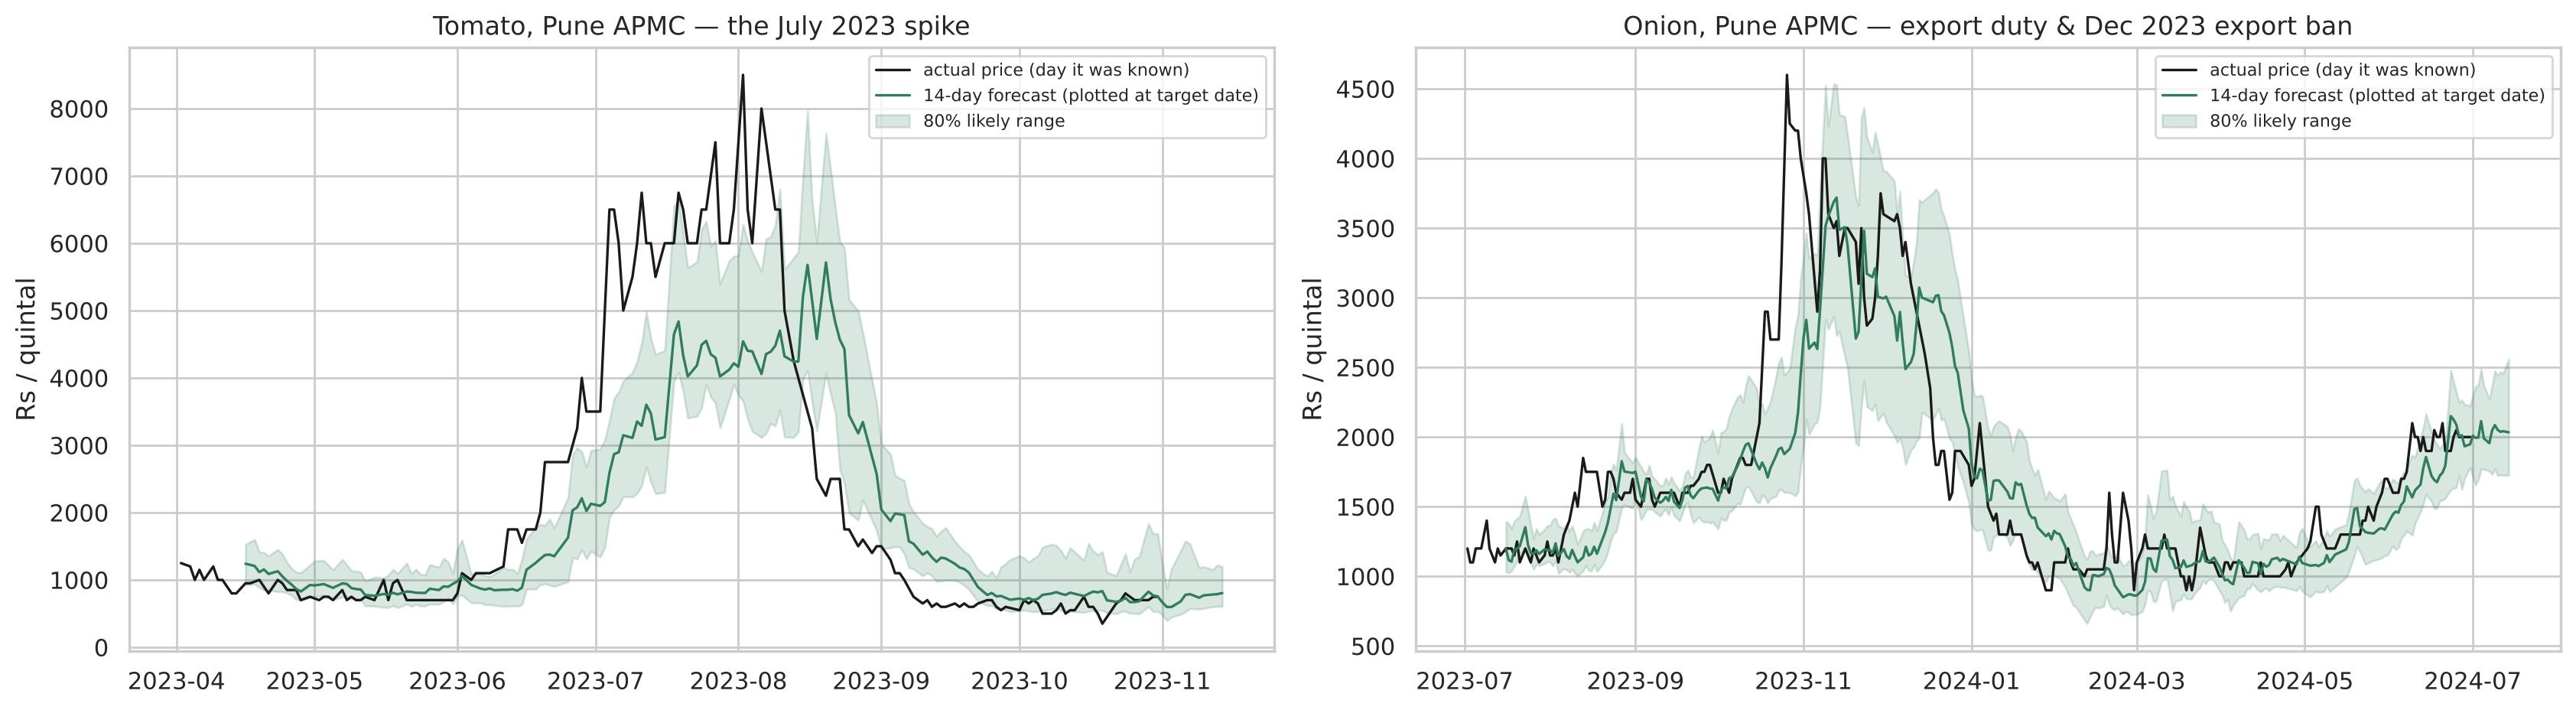

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
for a, (crop, mkt, start, end, title) in zip(ax, [("Tomato", "Pune", "2023-04-01", "2023-11-01", "Tomato, Pune APMC — the July 2023 spike"),
                                                  ("Onion", "Pune", "2023-07-01", "2024-07-01", "Onion, Pune APMC — export duty & Dec 2023 export ban")]):
    g = f14[(f14.crop == crop) & (f14.market == mkt) & (f14.date >= start) & (f14.date < end)].sort_values("date")
    tgt = g.date + pd.Timedelta(days=14)
    a.plot(g.date, g.price, c="k", lw=1.2, label="actual price (day it was known)")
    a.plot(tgt, g.price * np.exp(g["mid"]), c="#2E7D5B", lw=1.2, label="14-day forecast (plotted at target date)")
    a.fill_between(tgt, g.price * np.exp(g.lo), g.price * np.exp(g.hi), color="#2E7D5B", alpha=.18, label="80% likely range")
    a.set_title(title); a.set_ylabel("Rs / quintal"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "case_studies.png", dpi=120); plt.show()

The forecast follows the trend with a lag but **cannot see sudden policy shocks** (the export ban came overnight).
The range widens when the market becomes volatile, which is exactly when a farmer should be most careful.

### 12c. Farmer back-test: would following the advice have earned more?

Simulation on the 2023–2026 hold-out, for every crop, mandi and day: a farmer has 1 quintal to sell.
* **Always sell now** — the usual practice.
* **FarmStat advice** — hold for 14 days (onion, potato) or 7 days (tomato) only when the model expects a rise
  bigger than the storage loss (*4% per month onion, 3% potato, 15% tomato*); otherwise sell now.
Storage losses are subtracted from every hold.

In [19]:
COST = {"Onion": .04, "Potato": .03, "Tomato": .15}
bt = []
for crop in CROPS:
    h = 7 if crop == "Tomato" else 14
    fr = hold[h]["frame"]; fr = fr[fr.crop == crop]
    cost = COST[crop] * h / 30
    exp_gain = np.exp(fr["mid"]) - 1 - cost
    hold_it = exp_gain > 0.05
    realised = np.where(hold_it, fr.price * np.exp(fr[f"y_{h}"]) * (1 - cost), fr.price)
    bt.append(dict(crop=crop, hold_days=h, days=len(fr), advised_to_hold=hold_it.mean(),
                   holds_that_paid_off=np.mean((fr[f"y_{h}"][hold_it] > np.log(1 / (1 - cost)))),
                   avg_price_sell_now=fr.price.mean(), avg_price_with_advice=realised.mean(),
                   extra_Rs_per_quintal=realised.mean() - fr.price.mean(),
                   always_hold_Rs=(fr.price * np.exp(fr[f"y_{h}"]) * (1 - cost)).mean() - fr.price.mean()))
backtest = pd.DataFrame(bt).set_index("crop")
display(backtest.round(3))

,hold_days,days,advised_to_hold,holds_that_paid_off,avg_price_sell_now,avg_price_with_advice,extra_Rs_per_quintal,always_hold_Rs
crop,,,,,,,,
Onion,14,8748,0.231,0.704,1665.025,1712.507,47.482,-16.737
Tomato,7,7862,0.207,0.661,1835.044,1891.564,56.521,-59.840
Potato,14,6718,0.174,0.689,1505.668,1528.452,22.785,-22.949


A positive `extra_Rs_per_quintal` means following the advice earned more than selling immediately, after storage
losses; `always_hold_Rs` shows that blindly waiting is *not* the answer — the value comes from knowing **when** to wait.

### 12d. What drives the forecast?

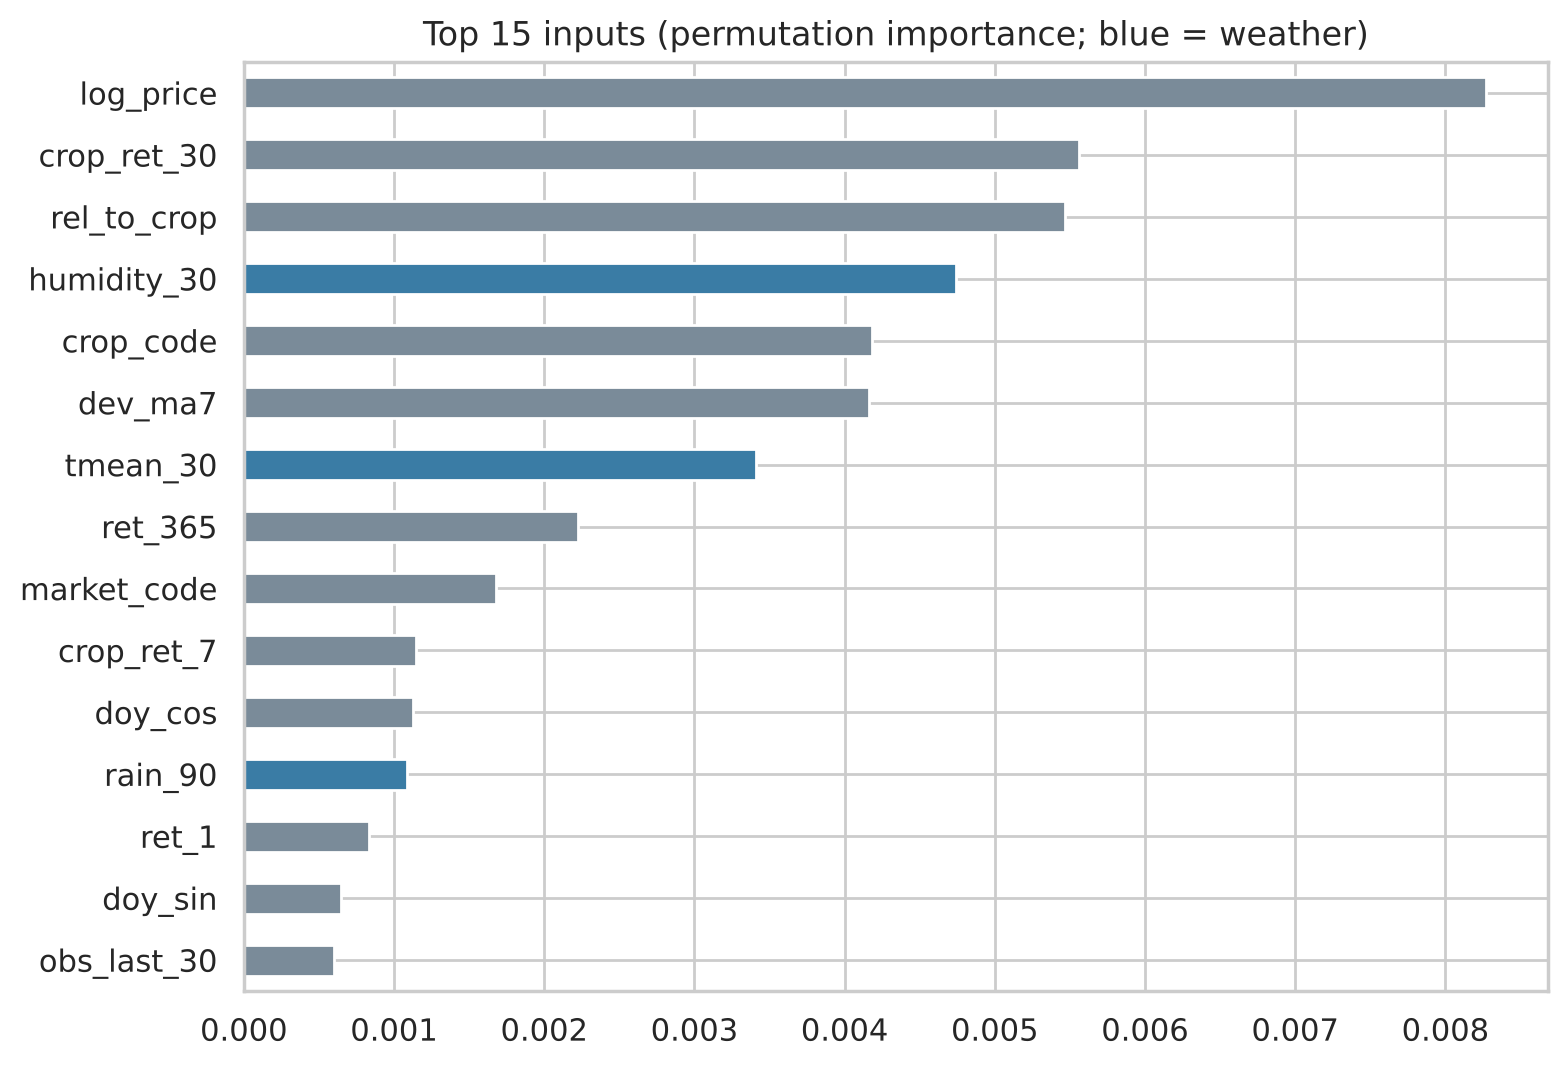

In [20]:
from sklearn.inspection import permutation_importance
sub = rng.choice(len(test), 8000, replace=False)
pi = permutation_importance(best_model, Xte.iloc[sub], yte[sub], scoring="neg_mean_absolute_error", n_repeats=4, random_state=SEED, n_jobs=2)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values().tail(15)
ax = imp.plot.barh(figsize=(8, 5.5), color=["#3A7CA5" if f in WEATHER_FEATURES else "#7A8B99" for f in imp.index])
ax.set_title("Top 15 inputs (permutation importance; blue = weather)"); plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=120); plt.show()

## 13. Final models

After validation, the final models are re-trained on **all** labelled data up to 2026 (the more recent the data,
the better for forecasting), with the tuned settings:
* 3 horizons × 3 quantiles = **9 gradient-boosting regressors**
* 1 **price-rise classifier** (14 days)

The hold-out scores above are the honest estimate of how these models perform on new data.

In [21]:
t0 = time.time()
final_q = {}
for h in HORIZONS:
    lab_h = ds[ds[f"y_{h}"].notna()]
    final_q[h] = quantile_models(lab_h[FEATURES], lab_h[f"y_{h}"].values)
lab14 = ds[ds["y_14"].notna()]
final_clf = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=100,
                                           l2_regularization=1.0, categorical_features=CAT, random_state=SEED)
final_clf.fit(lab14[FEATURES], (lab14["y_14"] > RISE).astype(int))
print(f"Final models trained on up to {len(lab14):,} rows in {time.time()-t0:.0f}s")

metrics = {
    "holdout_period": f"{test.date.min():%Y-%m-%d} to {test.date.max():%Y-%m-%d}",
    "horizons": {str(h): {k: float(v) for k, v in hold[h]["row"].items() if k != "model"} for h in HORIZONS},
    "walk_forward_skill_14d": {str(k): float(v) for k, v in wf["skill_vs_naive"].items()},
    "rise_classifier": {k: float(v) for k, v in cls_table.loc["Gradient Boosting"].items()},
    "backtest_extra_Rs_per_quintal": {c: float(v) for c, v in backtest["extra_Rs_per_quintal"].items()},
    "best_params": BEST, "n_rows": int(len(ds)), "data_until": f"{ds.date.max():%Y-%m-%d}",
}
bundle = dict(version="1.0.0", features=FEATURES, markets=MARKETS, quantile_models=final_q,
              rise_classifier=final_clf, metrics=metrics, sklearn_version=sklearn.__version__)
MODEL = ROOT / "models" / "farmstat_model.joblib"; MODEL.parent.mkdir(exist_ok=True)
joblib.dump(bundle, MODEL, compress=3)
(ROOT / "models" / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(f"Saved {MODEL.name} ({MODEL.stat().st_size / 1e6:.1f} MB)")

Final models trained on up to 68,734 rows in 43s


Saved farmstat_model.joblib (4.1 MB)


In [22]:
# Use the saved model exactly as the app does: latest forecast for every mandi
from farmstat.forecast import Forecaster
fc = Forecaster.load(MODEL)
latest = ds.sort_values("date").groupby(["crop", "market"]).tail(1)
latest = latest[latest.date >= ds.date.max() - pd.Timedelta(days=30)]
pred = fc.predict(latest)
view = latest[["crop", "market", "date", "price"]].join(pred[["p10_14", "p50_14", "p90_14", "prob_rise_14"]])
view["advice"] = [fc.advise(r.crop, r.price, pred.loc[i]).action for i, r in latest.iterrows()]
display(view.sort_values(["crop", "market"]).round(2).reset_index(drop=True))

,crop,market,date,price,p10_14,p50_14,p90_14,prob_rise_14,advice
0,Onion,Indapur,2026-08-19,2100.0,1466.65,2037.64,2599.78,0.23,Sell now
1,Onion,Junnar,2026-08-16,2700.0,2282.24,2824.94,3375.97,0.64,Your call
2,Onion,Junnar(Alephata),2026-08-18,3200.0,2398.07,3098.00,3896.13,0.53,Sell now
3,Onion,Junnar(Narayangaon),2026-08-19,2800.0,1933.30,2564.03,3386.27,0.32,Sell now
4,Onion,Junnar(Otur),2026-08-16,2350.0,2068.58,2399.51,3213.25,0.57,Your call
5,Onion,Khed(Chakan),2026-08-19,4000.0,2405.37,3212.42,4315.03,0.08,Sell now
6,Onion,Manchar,2026-08-18,4755.0,2492.82,3680.32,5371.70,0.13,Sell now
7,Onion,Pune,2026-08-17,2200.0,2034.54,2385.17,2833.19,0.64,Hold
8,Onion,Pune(Khadiki),2026-08-19,1050.0,1112.12,1301.51,1522.15,0.72,Hold
9,Onion,Pune(Manjri),2026-08-19,3500.0,2223.50,3171.13,3971.80,0.16,Sell now


## Conclusion

* **Model:** tuned Histogram Gradient Boosting (absolute-error / quantile loss) on 35 leakage-free features —
  past prices, district-wide trend, season and weather — for 7, 14 and 30 days ahead, plus a rise classifier.
* **Validated honestly:** time-based hold-out of 3.6 years (never touched during training), walk-forward
  cross-validation year by year, comparison with naive and moving-average baselines, per-crop / per-year / per-mandi
  breakdowns, range coverage, two case studies and a farmer back-test.
* **Course concepts:** preprocessing & outliers, EDA, feature engineering, 6 classic models, Random Forest /
  Gradient Boosting / XGBoost, GridSearchCV, PCA, K-Means with elbow & silhouette, regression *and* classification
  metrics, calibration, permutation importance.
* **Honest limits:** markets are close to unpredictable over a few days, so the gain over "no change" is modest at
  7 days and grows with the horizon. The model cannot foresee government decisions (export bans, duties) and does not
  yet use arrival volumes, which are a major price driver — the most valuable next feature to add.